# Preprocessing choices — evidence on real recordings

This notebook tests, on real Dräger PulmoVista 500 recordings, the choices made while designing the
fastEIT preprocessing layer (layer 2: from parsed `.bin` frames to a recording ready for breath-level
analysis). It is an **evidence notebook**: each section states a question, runs the comparison and
records the result. When a choice is confirmed, the section stays here as the supporting evidence.

**Status**: design phase — fastEIT has no preprocessing code yet. Reference implementations come from
[eitprocessing](https://github.com/EIT-ALIVE/eitprocessing) **v1.8.8** (Apache-2.0; Somhorst et al.,
JOSS 2026, DOI: 10.21105/joss.08179). Small prototypes written here are marked *prototype*.

| § | Question |
|---|----------|
| 1 | Which recordings are used? |
| 2 | Do fastEIT and eitprocessing read the same pixel values? |
| 3 | Does the Dräger `.bin` already contain a lung mask? |
| 4 | Can respiratory and heart rate be estimated from the pixels? |
| 5 | Which cardiac filter: Butterworth low-pass or MDN? |
| 6 | Are the device breath markers (`min_max_flag`) reliable? |
| 7 | Lung mask: TIV, amplitude or watershed — and is a simpler amplitude good enough? |

**Requirements** (not fastEIT dependencies — only to run this notebook):
`pip install eitprocessing==1.8.8 scikit-image`.
The anonymised test recordings are not distributed with the repository.

*Research use only — not a medical device.*

In [1]:
import copy
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap, ListedColormap
from scipy import signal
from skimage import feature, segmentation

import eitprocessing
from eitprocessing.datahandling.loading import load_eit_data
from eitprocessing.features.breath_detection import BreathDetection
from eitprocessing.features.rate_detection import RateDetection
from eitprocessing.filters.mdn import MDNFilter
from eitprocessing.roi.amplitude import AmplitudeLungspace
from eitprocessing.roi.tiv import TIVLungspace
from eitprocessing.roi.watershed import WatershedLungspace

import fasteit
from fasteit.parsers.loader import load_data

warnings.filterwarnings("ignore")  # eitprocessing emits many informational warnings
pd.set_option("display.precision", 2)

TEST_FILES = Path("../src/fasteit/test_files")
FILES = sorted(TEST_FILES.glob("*.bin"))
THRESHOLD = 0.15  # lung mask threshold, fraction of max TIV (eitprocessing default, Somhorst 2026)
PLOT_FILES = ["patient01_rec03.bin", "patient01_rec04.bin", "patient02.bin"]

# Reference palette (validated: categorical slots 1-3, CVD-safe)
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, INK2, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
SEQ = LinearSegmentedColormap.from_list("seq_blue", ["#cde2fb", "#86b6ef", "#2a78d6", "#1c5cab", "#0d366b"])
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": GRID,
    "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 1.5,
    "font.size": 10, "legend.frameon": False,
})
print(f"fastEIT {fasteit.__version__} | eitprocessing {eitprocessing.__version__} | {len(FILES)} recordings")

fastEIT 0.1.0.dev0 | eitprocessing 1.8.8 | 11 recordings


## Analysis helpers

All metrics are computed once per recording by `analyse()`; the sections below read from its results.
Helpers marked *prototype* are simplified versions written for this comparison, not fastEIT code.

In [2]:
def butterworth_lowpass(x, fs, cutoff, order=4):
    sos = signal.butter(order, cutoff, fs=fs, btype="low", output="sos")
    return signal.sosfiltfilt(sos, x, axis=0)


def power_near(x, fs, f0, half_width=0.1):
    # Welch power of x within f0 ± half_width Hz.
    f, p = signal.welch(x - x.mean(), fs, nperseg=min(len(x), int(30 * fs)))
    return p[(f >= f0 - half_width) & (f <= f0 + half_width)].sum()


def median_tiv_from_device_flags(g, flags):
    # Median tidal variation of g using the DEVICE markers (independent of our processing).
    peaks, valleys = np.flatnonzero(flags == 1), np.flatnonzero(flags == -1)
    tivs = [g[p] - g[valleys[valleys < p][-1]] for p in peaks if np.any(valleys < p)]
    return np.median(tivs)


def match_events(ref_t, det_t, tol=0.5):
    # Sensitivity (ref matched), PPV (det matched) and median |offset| within tol seconds.
    d = np.abs(ref_t[:, None] - det_t[None, :])
    hit_ref, hit_det = d.min(axis=1) <= tol, d.min(axis=0) <= tol
    return hit_ref.mean(), hit_det.mean(), np.median(d.min(axis=1)[hit_ref])


def prototype_masks(pix, breaths_idx, threshold=THRESHOLD):
    # *Prototype*: TIV map at global timing + simple amplitude (max - min inside each global breath),
    # then the watershed rule of eitprocessing (regions whose peak lies inside the TIV mask).
    tiv = np.mean([pix[p] - pix[s] for s, p, _ in breaths_idx], axis=0)
    amp = np.mean([pix[s:e].max(axis=0) - pix[s:e].min(axis=0) for s, _, e in breaths_idx], axis=0)
    thr_abs = threshold * np.nanmax(tiv)
    tiv_mask, amp_mask_abs = tiv >= thr_abs, amp >= thr_abs
    peaks = feature.peak_local_max(amp, exclude_border=False)
    markers = np.zeros(amp.shape, int)
    for i, (r, c) in enumerate(peaks, start=1):
        markers[r, c] = i
    regions = segmentation.watershed(-amp, markers)
    kept = [markers[r, c] for r, c in peaks if tiv_mask[r, c]]
    return tiv, amp, tiv_mask, np.isin(regions, kept) & amp_mask_abs


def as_bool(pixel_mask):
    return ~np.isnan(pixel_mask.mask)


def dice(a, b):
    return 2 * np.sum(a & b) / (a.sum() + b.sum())


def analyse(path):
    ours = load_data(path)
    eit = next(iter(load_eit_data(path, vendor="draeger").eit_data.values()))
    fs = eit.sample_frequency
    pix = np.asarray(eit.pixel_impedance, dtype=float)
    flags = np.asarray(ours.min_max_flags)
    r = {"file": path.name, "frames": len(pix), "fs_Hz": round(fs, 2), "minutes": len(pix) / fs / 60,
         "frame_format": ours.metadata["frame_format"]}

    # §2 parser cross-validation
    r["max_abs_pixel_diff"] = np.max(np.abs(np.asarray(ours.pixels, dtype=float) - pix))
    # §3 fixed outline
    r["active_pixels"] = int(np.any(pix != 0, axis=0).sum())
    # §4 rates
    rr, hr = RateDetection("adult").apply(eit, suppress_length_warnings=True, suppress_edge_case_warning=True)
    dev_peaks_t = np.flatnonzero(flags == 1) / fs
    r.update(rr_spectrum=rr * 60, rr_device_flags=len(dev_peaks_t) / r["minutes"], hr_spectrum=hr * 60)
    # §5 filters on the global signal
    g = pix.sum(axis=(1, 2))
    cutoff = (rr + hr) / 2
    g_bw = butterworth_lowpass(g, fs, cutoff)
    g_mdn = MDNFilter(respiratory_rate=rr, heart_rate=hr).apply(g, sample_frequency=fs)
    tiv_raw = median_tiv_from_device_flags(g, flags)
    r.update(
        cutoff_Hz=cutoff,
        tiv_kept_butterworth_pct=100 * median_tiv_from_device_flags(g_bw, flags) / tiv_raw,
        tiv_kept_mdn_pct=100 * median_tiv_from_device_flags(g_mdn, flags) / tiv_raw,
        cardiac_dB_butterworth=10 * np.log10(power_near(g_bw, fs, hr) / power_near(g, fs, hr)),
        cardiac_dB_mdn=10 * np.log10(power_near(g_mdn, fs, hr) / power_near(g, fs, hr)),
    )
    # §6 breath detection on the MDN-filtered pixels vs device flags
    eit_f = copy.deepcopy(eit)
    eit_f.pixel_impedance = MDNFilter(respiratory_rate=rr, heart_rate=hr).apply(pix, sample_frequency=fs, axis=0)
    breaths = BreathDetection().find_breaths(eit_f.get_summed_impedance()).values
    det_peaks_t = np.array([b.middle_time for b in breaths]) - eit.time[0]
    sens, ppv, offset = match_events(dev_peaks_t, det_peaks_t)
    r.update(breaths_detected=len(breaths), breaths_device=len(dev_peaks_t),
             sensitivity=sens, ppv=ppv, median_offset_s=offset)
    # §7 lung masks
    idx = [tuple(np.searchsorted(eit.time, [b.start_time, b.middle_time, b.end_time])) for b in breaths]
    pix_f = np.asarray(eit_f.pixel_impedance, dtype=float)
    tiv_map, amp_map, tiv_proto, ws_proto = prototype_masks(pix_f, idx)
    tiv_ref = as_bool(TIVLungspace(threshold=THRESHOLD).apply(eit_f))
    amp_ref = as_bool(AmplitudeLungspace(threshold=THRESHOLD).apply(eit_f))
    ws_ref = as_bool(WatershedLungspace(threshold_fraction=THRESHOLD).apply(eit_f))
    r.update(px_tiv_ref=int(tiv_ref.sum()), px_tiv_proto=int(tiv_proto.sum()), dice_tiv=dice(tiv_ref, tiv_proto),
             px_amplitude_ref=int(amp_ref.sum()), px_watershed_ref=int(ws_ref.sum()),
             px_watershed_proto=int(ws_proto.sum()), dice_watershed=dice(ws_ref, ws_proto))

    keep = None
    if path.name in PLOT_FILES:
        keep = dict(fs=fs, g=g, g_bw=g_bw, g_mdn=g_mdn, rr=rr, hr=hr, pix_active=np.any(pix != 0, axis=0),
                    g_f=pix_f.sum(axis=(1, 2)), det_peaks_t=det_peaks_t, dev_peaks_t=dev_peaks_t,
                    tiv_map=tiv_map, amp_map=amp_map, tiv_ref=tiv_ref, ws_ref=ws_ref, ws_proto=ws_proto)
    return r, keep


results, cache = [], {}
for path in FILES:
    r, keep = analyse(path)
    results.append(r)
    if keep is not None:
        cache[path.name] = keep
res = pd.DataFrame(results).set_index("file")
print(f"analysed {len(res)} recordings")

analysed 11 recordings


## 1. Recordings

Eleven anonymised Dräger PulmoVista 500 `.bin` recordings: one healthy volunteer (20 Hz) and two
ICU patients (50 Hz). Patient 01 contributes nine recordings.

**Side finding.** All files use the 4382-byte frame layout, including the healthy volunteer, who had no
PressurePod connected (Pod channels 54–57 contain the "not connected" sentinel; see
`docs/reverse_eng/draeger_bin_format.ipynb`). The parser metadata field `has_pressure_pod` is derived
from the frame layout, so it reads `True` for this file too: it reports the *format*, not whether the
Pod was connected. To be fixed in the parser.

In [3]:
res[["frames", "fs_Hz", "minutes", "frame_format"]]

,frames,fs_Hz,minutes,frame_format
file,,,,
01_Healthy_Lung_01.bin,1118,20.00,0.93,Draeger_ext_4382
patient01_rec02.bin,1600,50.00,0.53,Draeger_ext_4382
patient01_rec03.bin,5750,50.00,1.92,Draeger_ext_4382
patient01_rec04.bin,11250,50.00,3.75,Draeger_ext_4382
patient01_rec05.bin,11500,50.00,3.83,Draeger_ext_4382
patient01_rec07.bin,10050,50.00,3.35,Draeger_ext_4382
patient01_rec09.bin,7200,50.00,2.40,Draeger_ext_4382
patient01_rec11.bin,8250,49.97,2.75,Draeger_ext_4382
patient01_rec12.bin,6600,50.00,2.20,Draeger_ext_4382


## 2. Parser cross-validation: fastEIT vs eitprocessing

**Question.** Do the two independent `.bin` parsers return the same pixel values?

**Result.** The maximum absolute difference is 0 in every recording: the parsers agree bit for bit.
(eitprocessing estimates `fs` by regression, so `patient01_rec11` reads 49.97 Hz instead of 50.)

In [4]:
res[["frames", "fs_Hz", "max_abs_pixel_diff"]]

,frames,fs_Hz,max_abs_pixel_diff
file,,,
01_Healthy_Lung_01.bin,1118,20.00,0.0
patient01_rec02.bin,1600,50.00,0.0
patient01_rec03.bin,5750,50.00,0.0
patient01_rec04.bin,11250,50.00,0.0
patient01_rec05.bin,11500,50.00,0.0
patient01_rec07.bin,10050,50.00,0.0
patient01_rec09.bin,7200,50.00,0.0
patient01_rec11.bin,8250,49.97,0.0
patient01_rec12.bin,6600,50.00,0.0


## 3. Does the `.bin` contain a lung mask?

**Question.** Has the Dräger software already removed non-lung pixels?

**Result.** No. Only the 29 corner pixels are always zero, and the active region is **identical in
every recording**, including the healthy volunteer. It is the fixed geometric outline of the
reconstruction domain, not a functional lung mask, which would differ between patients and with
ventilation. A lung mask has to be computed (§7). eitprocessing makes the same assumption: its Dräger
loader applies no mask and its lung-space methods run on Dräger data.

active_pixels
995    11
Name: recordings with this many active pixels, dtype: int64


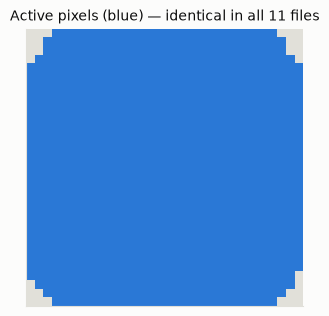

In [5]:
print(res["active_pixels"].value_counts().rename("recordings with this many active pixels"))
active = cache["patient02.bin"]["pix_active"]
fig, ax = plt.subplots(figsize=(3.6, 3.6))
ax.imshow(active, cmap=ListedColormap([GRID, BLUE]), interpolation="nearest")
ax.set_title("Active pixels (blue) — identical in all 11 files", fontsize=10)
ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
plt.show()

## 4. Respiratory and heart rate from the pixels

**Question.** An adaptive cardiac filter needs the respiratory rate (RR) and heart rate (HR). Can they
be estimated from the image data? Method: eitprocessing `RateDetection` (Welch spectrum; HR from pixels
where the cardiac component is relatively strong). RR is cross-checked against the device breath markers.

**Result.**
- RR agrees with the device markers within 1.7 breaths/min in every recording.
- HR is implausible in two recordings (`rec02` 41.5/min, `rec03` exactly 40.0/min): 40/min is the
  **lower limit** of the adult search range, so the estimate is stuck at the boundary. Patient 01 has
  HR 62–118/min in the other recordings.
- The spectrum of `rec03` (right plot below) still shows a clear peak near 107/min, matching the HR of the
  same patient in the other recordings (106–112/min): the heart rate *is* in the data, the estimator picked
  the wrong maximum (the range edge on the slope of the respiratory peak).
- **Consequence for the design:** an HR estimate at (or near) the edge of the search range must be
  flagged as unreliable and trigger a fallback, not be used silently.

In [6]:
rates = res[["rr_spectrum", "rr_device_flags", "hr_spectrum"]].copy()
rates["rr_difference"] = rates.rr_spectrum - rates.rr_device_flags
rates["hr_at_range_edge"] = rates.hr_spectrum < 42
rates

,rr_spectrum,rr_device_flags,hr_spectrum,rr_difference,hr_at_range_edge
file,,,,,
01_Healthy_Lung_01.bin,10.24,10.73,64.07,-0.49,False
patient01_rec02.bin,30.18,30.00,41.47,0.18,True
patient01_rec03.bin,30.25,29.74,40.00,0.51,True
patient01_rec04.bin,30.67,31.47,108.18,-0.80,False
patient01_rec05.bin,29.34,27.65,87.70,1.69,False
patient01_rec07.bin,31.25,30.45,62.18,0.80,False
patient01_rec09.bin,30.08,28.75,106.47,1.33,False
patient01_rec11.bin,33.66,33.07,112.56,0.58,False
patient01_rec12.bin,41.69,40.45,118.44,1.24,False


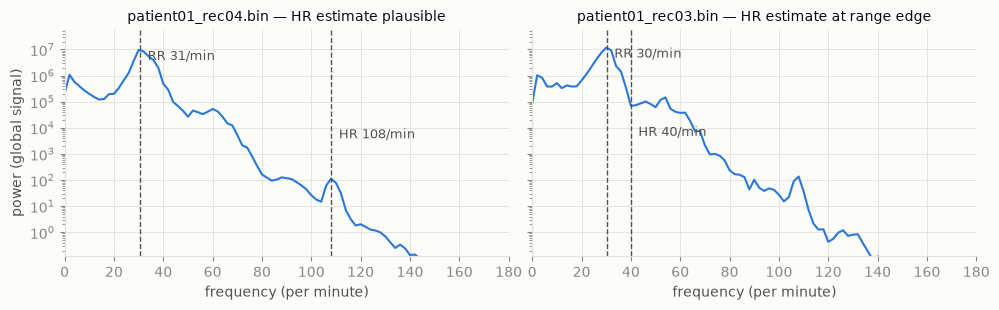

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), sharey=True)
for ax, name, label in zip(axes, ["patient01_rec04.bin", "patient01_rec03.bin"], ["HR estimate plausible", "HR estimate at range edge"]):
    c = cache[name]
    f, p = signal.welch(c["g"] - c["g"].mean(), c["fs"], nperseg=int(30 * c["fs"]))
    ax.semilogy(f * 60, p, color=BLUE)
    for value, text, height in [(c["rr"] * 60, "RR", 1.0), (c["hr"] * 60, "HR", 1e-3)]:
        ax.axvline(value, color=INK2, linestyle="--", linewidth=1)
        ax.text(value + 3, p.max() * height, f"{text} {value:.0f}/min", color=INK2, fontsize=9, va="top")
    ax.set_xlim(0, 180); ax.set_ylim(p.max() * 1e-8, p.max() * 5)
    ax.set_xlabel("frequency (per minute)")
    ax.set_title(f"{name} — {label}", fontsize=10)
axes[0].set_ylabel("power (global signal)")
plt.tight_layout(); plt.show()

## 5. Cardiac filter: Butterworth low-pass vs MDN

**Question.** Which filter removes the cardiac component without distorting the breaths?

- *Butterworth low-pass* (4th order, zero phase), cutoff halfway between RR and HR.
- *MDN* (multiple digital notch; Wisse et al., Physiol Meas 2024, DOI: 10.1088/1361-6579/ad46e3),
  eitprocessing implementation: one band-stop per cardiac harmonic, then a low-pass at 220/min.

Two measures per recording: **tidal variation kept** (median TIV of the global signal after filtering,
as % of the unfiltered value, measured at the *device* breath markers so it does not depend on our
processing) and **cardiac power removed** (power around HR, in dB).

**Result.**
- These patients breathe at 28–42/min (0.5–0.7 Hz). A low-pass placed between RR and HR also removes
  respiratory harmonics: Butterworth keeps 87–100 % of the TIV when HR is estimated correctly
  (lowest when HR is close to RR, e.g. `patient02`, `rec07`).
- MDN keeps 99–101 % of the TIV and removes more cardiac power (−33 to −45 dB vs −13 to −35 dB).
- When the HR estimate fails (`rec02`, `rec03`) neither filter works: Butterworth loses 24–29 % of the
  TIV. This confirms the need for the HR plausibility check of §4.

In [8]:
res[["rr_spectrum", "hr_spectrum", "cutoff_Hz", "tiv_kept_butterworth_pct", "tiv_kept_mdn_pct", "cardiac_dB_butterworth", "cardiac_dB_mdn"]]

,rr_spectrum,hr_spectrum,cutoff_Hz,tiv_kept_butterworth_pct,tiv_kept_mdn_pct,cardiac_dB_butterworth,cardiac_dB_mdn
file,,,,,,,
01_Healthy_Lung_01.bin,10.24,64.07,0.62,100.50,101.39,-35.40,-43.28
patient01_rec02.bin,30.18,41.47,0.60,76.37,97.35,-9.65,-3.94
patient01_rec03.bin,30.25,40.00,0.59,70.61,92.37,-5.32,-1.70
patient01_rec04.bin,30.67,108.18,1.16,99.23,100.21,-31.17,-40.46
patient01_rec05.bin,29.34,87.70,0.98,99.32,100.17,-26.95,-34.61
patient01_rec07.bin,31.25,62.18,0.78,93.48,99.23,-18.69,-44.58
patient01_rec09.bin,30.08,106.47,1.14,99.42,100.17,-31.08,-43.78
patient01_rec11.bin,33.66,112.56,1.22,99.48,99.73,-30.43,-45.08
patient01_rec12.bin,41.69,118.44,1.33,99.02,99.99,-27.74,-44.79


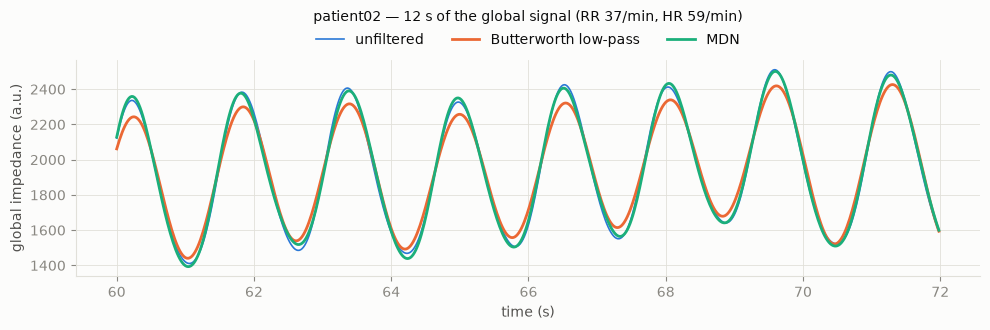

In [9]:
c = cache["patient02.bin"]
t = np.arange(len(c["g"])) / c["fs"]
win = (t >= 60) & (t < 72)
fig, ax = plt.subplots(figsize=(10, 3.4))
for y, color, label in [(c["g"], BLUE, "unfiltered"), (c["g_bw"], ORANGE, "Butterworth low-pass"), (c["g_mdn"], AQUA, "MDN")]:
    ax.plot(t[win], y[win], color=color, label=label, linewidth=2 if label != "unfiltered" else 1.2)
ax.set_xlabel("time (s)"); ax.set_ylabel("global impedance (a.u.)")
ax.set_title("patient02 — 12 s of the global signal (RR 37/min, HR 59/min)", fontsize=10, pad=28)
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=3)
plt.tight_layout(); plt.show()

## 6. Breath detection vs device markers

**Question.** Are the breath markers written by the PulmoVista (`min_max_flag`, +1 = end-inspiratory
peak) reliable, and do they agree with an algorithmic detection? Detection: eitprocessing
`BreathDetection` on the MDN-filtered global signal. A device peak and a detected peak match when they
are within 0.5 s.

**Result.**
- Every detected breath but one corresponds to a device marker (PPV ≥ 0.99).
- 80–99 % of the device markers are matched; the unmatched ones are mostly at the start and end of the
  recording, where the algorithm discards incomplete breaths by design.
- Median timing difference ≤ 0.06 s (at most 3 frames at 50 Hz; 0 in six recordings).
- The device markers are therefore usable as a breath-detection method (`device_flags`) and as a
  reference to validate other methods.

In [10]:
res[["breaths_detected", "breaths_device", "sensitivity", "ppv", "median_offset_s"]].round(3)

,breaths_detected,breaths_device,sensitivity,ppv,median_offset_s
file,,,,,
01_Healthy_Lung_01.bin,8,10,0.80,1.00,0.00
patient01_rec02.bin,14,16,0.88,1.00,0.06
patient01_rec03.bin,55,57,0.96,1.00,0.02
patient01_rec04.bin,117,118,0.98,0.99,0.00
patient01_rec05.bin,104,106,0.98,1.00,0.00
patient01_rec07.bin,100,102,0.98,1.00,0.02
patient01_rec09.bin,68,69,0.99,1.00,0.00
patient01_rec11.bin,89,91,0.98,1.00,0.05
patient01_rec12.bin,88,89,0.99,1.00,0.00


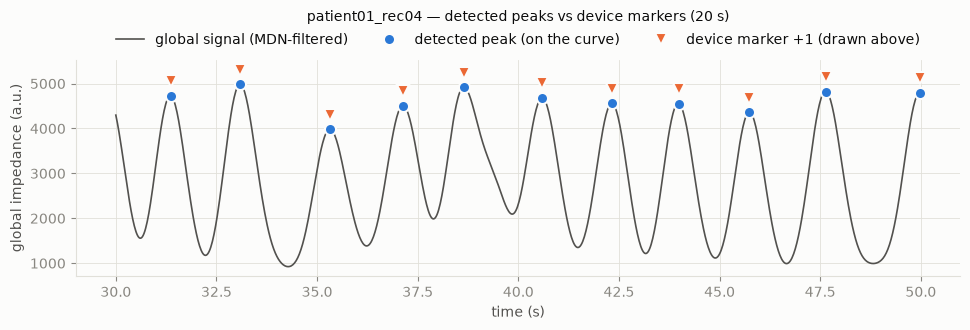

In [11]:
c = cache["patient01_rec04.bin"]
t = np.arange(len(c["g_f"])) / c["fs"]
win = (t >= 30) & (t < 50)
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.plot(t[win], c["g_f"][win], color=INK2, linewidth=1.2, label="global signal (MDN-filtered)")
lift = 0.08 * np.ptp(c["g_f"][win])  # device markers drawn just above the peak so both stay visible
for times, color, marker, dy, label in [(c["det_peaks_t"], BLUE, "o", 0, "detected peak (on the curve)"),
                                        (c["dev_peaks_t"], ORANGE, "v", lift, "device marker +1 (drawn above)")]:
    sel = times[(times >= 30) & (times < 50)]
    ax.plot(sel, np.interp(sel, t, c["g_f"]) + dy, linestyle="none", marker=marker, markersize=8,
            color=color, markeredgecolor=SURFACE, markeredgewidth=1.5, label=label)
ax.set_xlabel("time (s)"); ax.set_ylabel("global impedance (a.u.)")
ax.set_title("patient01_rec04 — detected peaks vs device markers (20 s)", fontsize=10, pad=28)
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=3)
plt.tight_layout(); plt.show()

## 7. Lung mask: TIV, amplitude, watershed

**Question 1.** How different are the three eitprocessing methods on real data (threshold 15 %)?
**Question 2.** Is a *prototype* with a simpler amplitude (max − min of each pixel inside each global
breath, instead of eitprocessing's phase-shift-corrected pixel breaths) close enough to the reference
watershed?

**Result.**
- *TIV prototype vs eitprocessing `TIVLungspace`*: identical masks in every recording (Dice 1.00) —
  the TIV formula is confirmed.
- *Amplitude alone* includes up to 84 more pixels than TIV. In the `patient02` maps below it picks up a
  ventral high-amplitude region between the lungs (probably cardiac or vascular) that TIV and watershed
  both leave out.
- *Watershed* adds 1–49 pixels to the TIV mask: the out-of-phase pixels it is designed to recover.
  It is not strictly "between" TIV and amplitude: in four recordings it includes a few more pixels than
  amplitude alone, because its amplitude threshold is 15 % of the max **TIV** (an absolute value lower
  than the 15 % of the max amplitude used by `AmplitudeLungspace`).
- *Watershed prototype vs reference*: Dice 0.96–1.00, but the prototype is **systematically larger**
  (+1 to +33 pixels), because max − min inside a breath also captures within-breath drift and noise.
  Close, but not identical: see the summary for the decision this informs.

In [12]:
res[["px_tiv_ref", "px_tiv_proto", "dice_tiv", "px_amplitude_ref", "px_watershed_ref", "px_watershed_proto", "dice_watershed"]]

,px_tiv_ref,px_tiv_proto,dice_tiv,px_amplitude_ref,px_watershed_ref,px_watershed_proto,dice_watershed
file,,,,,,,
01_Healthy_Lung_01.bin,511,511,1.0,512,512,513,1.00
patient01_rec02.bin,368,368,1.0,395,372,385,0.98
patient01_rec03.bin,371,371,1.0,388,381,401,0.97
patient01_rec04.bin,353,353,1.0,365,369,384,0.98
patient01_rec05.bin,367,367,1.0,367,370,372,1.00
patient01_rec07.bin,351,351,1.0,356,356,359,1.00
patient01_rec09.bin,351,351,1.0,371,373,388,0.98
patient01_rec11.bin,374,374,1.0,429,391,421,0.96
patient01_rec12.bin,335,335,1.0,405,381,414,0.96


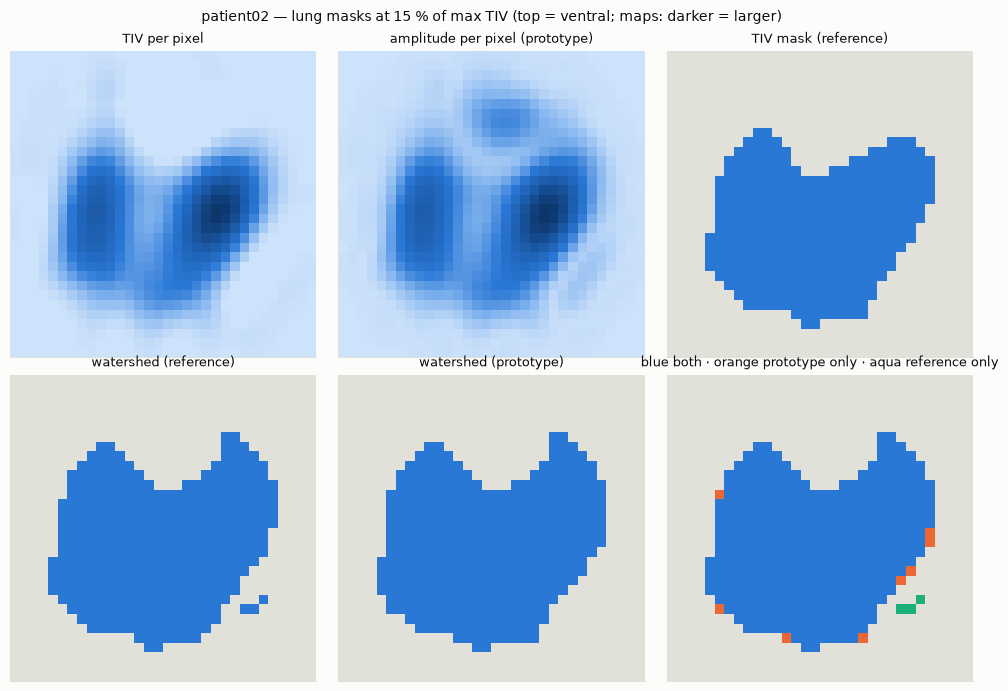

In [13]:
c = cache["patient02.bin"]
both = c["ws_ref"] & c["ws_proto"]
diff = np.zeros(c["ws_ref"].shape, int)
diff[both] = 1; diff[c["ws_proto"] & ~c["ws_ref"]] = 2; diff[c["ws_ref"] & ~c["ws_proto"]] = 3
panels = [
    (c["tiv_map"], SEQ, "TIV per pixel"), (c["amp_map"], SEQ, "amplitude per pixel (prototype)"),
    (c["tiv_ref"], ListedColormap([GRID, BLUE]), "TIV mask (reference)"),
    (c["ws_ref"], ListedColormap([GRID, BLUE]), "watershed (reference)"),
    (c["ws_proto"], ListedColormap([GRID, BLUE]), "watershed (prototype)"),
    (diff, ListedColormap([GRID, BLUE, ORANGE, AQUA]), "blue both · orange prototype only · aqua reference only"),
]
fig, axes = plt.subplots(2, 3, figsize=(10, 7))
for ax, (img, cmap, title) in zip(axes.ravel(), panels):
    ax.imshow(img, cmap=cmap, interpolation="nearest", vmin=0 if img.dtype != bool else None)
    ax.set_title(title, fontsize=9); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
fig.suptitle("patient02 — lung masks at 15 % of max TIV (top = ventral; maps: darker = larger)", fontsize=10)
plt.tight_layout(); plt.show()